In [1]:
%matplotlib inline
import os
import re
import itertools
from itertools import combinations
import glob
import pickle
import argparse

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import multiprocess as mp
import numpy as np
import pandas as pd
import bioframe as bf
from bioframe import overlap
#import cooltools
import cooler
from matplotlib import gridspec
from matplotlib.gridspec import GridSpec
import matplotlib.colors as colors
from matplotlib.colors import ListedColormap
import gzip
from numpy import diff
from scipy import signal
import scipy.ndimage
from collections import OrderedDict

In [2]:
##using pairtools to selected chr1: 
#pairtools select '(chrom1==chrom2) and (chrom1=="chr1")' -o G1_merge_chr1.pairs G1_merge.hg38.nodups.pairs.gz
#pairtools select '(chrom1==chrom2) and (chrom1=="chr1")' -o proM_merge_chr1.pairs proM_merge.hg38.nodups.pairs.gz

In [2]:
#benchmark pseudobulk (two batches)
path = "/home/xiangru.huo-umw/scHiC/benchmark/scHiC_0115_2023/results_12merge/pairs_library/"

condition = [
    'G1_merge',  
    'proM_merge']
    
import os
os.chdir(path)
#print(os.getcwd())

pairs_header = ['read_id', 'chrom1', 'pos1', 'chrom2', 'pos2', 'strand1', 'strand2', 'pair_type', 'mapq1', 'mapq2']

batch2_dfs = {}
batch2_contacts = {}
for cond in condition:
    filename = cond + '.hg38.nodups.pairs.gz'
    with gzip.open(filename, 'rt') as file:
        df = pd.read_csv(
            filename,
            sep="\t",
            header=None,
            comment="#",
            names=pairs_header,
            index_col=None
        )
    Num_Cont = len(df)
    batch2_contacts[cond] = Num_Cont
    batch2_dfs[cond] = {'df': df}

    
#benchmark pseudobulk (the other batch)
path = "/home/xiangru.huo-umw/scHiC/benchmark/scHiC_1203_2022/1+2_sc_results/pairs_library"
    
import os
os.chdir(path)
os.getcwd()

pairs_header = ['read_id', 'chrom1', 'pos1', 'chrom2', 'pos2', 'strand1', 'strand2', 'pair_type', 'mapq1', 'mapq2']

batch1_dfs = {}
batch1_contacts = {}
for cond in condition:
    filename = cond + '.hg38.nodups.pairs.gz'
    with gzip.open(filename, 'rt') as file:
        df = pd.read_csv(
            filename,
            sep="\t",
            header=None,
            comment="#",
            names=pairs_header,
            index_col=None
        )
    Num_Cont = len(df)
    batch1_contacts[cond] = Num_Cont
    batch1_dfs[cond] = {'df': df}
    
    
    
#combine two plates
Combined_dfs = {}

for cond in condition:
    batch1_df = batch1_dfs[cond]['df']
    batch2_df = batch2_dfs[cond]['df']
    
    Combined_dfs[cond] = {'batch1': batch1_df, 'batch2': batch2_df}
    
Num_Contacts = {}
Num_Contacts = {'batch1': batch1_contacts, 'batch2': batch2_contacts}

In [ ]:
import os
import gzip

# ============================================================
# Output file
# ============================================================

output_file = (
    "/home/xiangru.huo-umw/scHiC/GEO_processed_data/"
    "G1-proM_plate_based_merge_batches.pair.gz"
)

os.makedirs(os.path.dirname(output_file), exist_ok=True)

pairs_header = [
    "read_id",
    "chrom1",
    "pos1",
    "chrom2",
    "pos2",
    "strand1",
    "strand2",
    "pair_type",
    "mapq1",
    "mapq2"
]

# ============================================================
# Merge the two loaded batches
# ============================================================

total_contacts = 0
total_samples = 0

with gzip.open(output_file, "wt") as out:

    # Header
    out.write("#Combined G1 and proM pseudobulk Hi-C pairs\n")
    out.write(
        "#columns: batch_id\tcell_id\t"
        + "\t".join(pairs_header)
        + "\n"
    )

    for cond in condition:

        # Remove "_merge"
        # G1_merge -> G1
        # proM_merge -> proM
        cell_type = cond.replace("_merge", "")

        # ====================================================
        # Batch 1
        # ====================================================

        batch1_df = batch1_dfs[cond]["df"].copy()

        batch1_df.insert(
            0,
            "cell_id",
            f"Batch1_scHiC_{cell_type}_10"
        )

        batch1_df.insert(
            0,
            "batch_id",
            "Batch1"
        )

        batch1_df.to_csv(
            out,
            sep="\t",
            index=False,
            header=False
        )

        total_contacts += len(batch1_df)
        total_samples += 1

        print(
            f"Batch1_scHiC_{cell_type}_10: "
            f"{len(batch1_df):,} contacts"
        )

        # ====================================================
        # Batch 2
        # ====================================================

        batch2_df = batch2_dfs[cond]["df"].copy()

        batch2_df.insert(
            0,
            "cell_id",
            f"Batch2_{cell_type}_plate2_10"
        )

        batch2_df.insert(
            0,
            "batch_id",
            "Batch2"
        )

        batch2_df.to_csv(
            out,
            sep="\t",
            index=False,
            header=False
        )

        total_contacts += len(batch2_df)
        total_samples += 1

        print(
            f"Batch2_{cell_type}_plate2_10: "
            f"{len(batch2_df):,} contacts"
        )

print("\nFinished merging")
print(f"Total samples: {total_samples}")
print(f"Total contacts: {total_contacts:,}")
print(f"Saved to:\n{output_file}")

Batch1_scHiC_G1_10: 4,441,097 contacts
Batch2_G1_plate2_10: 6,000,571 contacts
Batch1_scHiC_proM_10: 9,454,792 contacts


In [4]:
# Use bioframe to fetch the genomic features from the UCSC.
hg38_chromsizes = bf.fetch_chromsizes('hg38')
hg38_cens = bf.fetch_centromeres('hg38')
# create a view with chromosome arms using chromosome sizes and definition of centromeres
hg38_arms = bf.make_chromarms(hg38_chromsizes,  hg38_cens)
hg38_arms['arm'] = hg38_arms['name'].str.split('_').str[1]

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/bioframe/io/fileops.py:281: FutureWarning: The provided callable <function amin at 0x14c278c98040> is currently using SeriesGroupBy.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  cens = cens.groupby("chrom").agg({"start": np.min, "end": np.max}).reset_index()
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/bioframe/io/fileops.py:281: FutureWarning: The provided callable <function amax at 0x14c278c8fe20> is currently using SeriesGroupBy.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.
  cens = cens.groupby("chrom").agg({"start": np.min, "end": np.max}).reset_index()


In [5]:
#caculate the distance and only preserve "chrom1 == chrom 2"&&"arm1 == arm2" (intra-chrom contacts within arm)
Pseudobulk_contacts_dfs = {cond: {batch: {} for batch in ['batch1','batch2']} for cond in condition}

for cond in condition:
    for batch in ['batch1','batch2']:
        df = Combined_dfs[cond][batch].copy()
        df = df.loc[:,['chrom1','pos1','chrom2','pos2']]
        #get two position separately
        df["pos1+1"] = df["pos1"] +1
        df["pos2+1"] = df["pos2"] +1
        df_pos1 = df.loc[:,['chrom1','pos1','pos1+1']]
        df_pos1.columns =['chrom', 'start', 'end']
        df_pos2 = df.loc[:,['chrom2','pos2','pos2+1']]
        df_pos2.columns =['chrom', 'start', 'end']
        #get compartment info for each locus
        pos1_arm_intervals = bf.overlap(df_pos1,hg38_arms, how='left', suffixes=('_1','_2'))
        pos2_arm_intervals = bf.overlap(df_pos2,hg38_arms,  how='left', suffixes=('_1','_2'))
        #pick up specific column
        pos1_arm_intervals = pos1_arm_intervals.loc[:,["chrom_1","start_1","arm_2"]]
        pos1_arm_intervals.columns = ["chrom1","pos1","arm1"]
        pos2_arm_intervals = pos2_arm_intervals.loc[:,["chrom_1","start_1","arm_2"]]
        pos2_arm_intervals.columns = ["chrom2","pos2","arm2"]
        #two position organized
        pos1_2 = pd.concat([pos1_arm_intervals,pos2_arm_intervals], axis=1)
        pos1_2 = pos1_2[pos1_2['chrom1'] == pos1_2['chrom2']]
        pos1_2 = pos1_2[pos1_2['arm1'] == pos1_2['arm2']]
        pos1_2['dist'] = pos1_2['pos1']-pos1_2['pos2']
        pos1_2['Abs_Dist'] = abs(pos1_2['dist'].copy()).astype(float)
    
        Pseudobulk_contacts_dfs[cond][batch] = pos1_2
        
Pseudobulk_contacts_dfs[cond][batch]

,chrom1,pos1,arm1,chrom2,pos2,arm2,dist,Abs_Dist
0,chr1,10001,p,chr1,10129,p,-128,128.0
1,chr1,10002,p,chr1,10135,p,-133,133.0
2,chr1,10003,p,chr1,10129,p,-126,126.0
3,chr1,10010,p,chr1,10110,p,-100,100.0
4,chr1,10016,p,chr1,10110,p,-94,94.0
...,...,...,...,...,...,...,...,...
3964921,chrY,56878337,q,chrY,56878345,q,-8,8.0
3964922,chrY,56878975,q,chrY,56879390,q,-415,415.0
3964923,chrY,56878978,q,chrY,56879390,q,-412,412.0
3964924,chrY,56880486,q,chrY,56880713,q,-227,227.0


In [63]:
#filter contacts distance > 0
dist_df = pd.DataFrame()  
for cond in condition:
    for batch in ['batch1','batch2']:
        dist_dropna = pd.DataFrame({'Abs_Dist': Pseudobulk_contacts_dfs[cond][batch]['Abs_Dist'].copy(),
                                    'Condition': cond})
        dist_dropna = dist_dropna.replace([np.inf, -np.inf], np.nan).dropna()
        dist_df = pd.concat([dist_df, dist_dropna[dist_dropna['Abs_Dist'] > 0]], ignore_index=True)

<Figure size 1200x900 with 0 Axes>

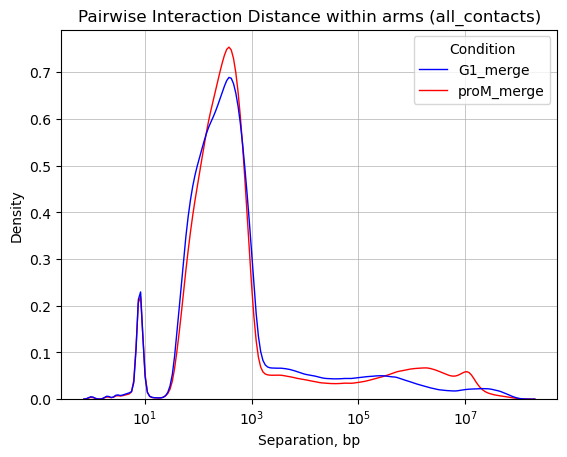

In [64]:
#identified samplecolor
samplecolor = {'proM_merge':'red','G1_merge':'blue'}

#plot the density of pairwise contaction
plt.figure(figsize=(4, 3), dpi=300)
fig, ax = plt.subplots()
sns.kdeplot(data = dist_df, 
            x = 'Abs_Dist',
            common_norm = False,
            lw = 1, 
            log_scale = True, 
            common_grid = True,
            hue='Condition',
            palette=samplecolor)
plt.xlabel('Separation, bp')
plt.ylabel('Density')
plt.title('Pairwise Interaction Distance within arms (all_contacts)')
plt.grid(lw=0.5)
#plt.legend(bbox_to_anchor=(1.04,1), loc="upper left")
plt.show()
#sns.move_legend(g, "upper left", bbox_to_anchor=(1.05, 1), title='Sample')  

In [65]:
#filter contacts distance > 2000bp 
dist_df = pd.DataFrame() 
cond = 'G1_merge'
samplecolor = {"G1_merge": 'blue'}
distance = 2000
#samplecolor = {'batch1':'#028A0F','batch2':'#03C04A','random':'#D9DDDC'}
#for cond in condition:
for batch in ['batch1','batch2']: # or add "random"
        dist_dropna = pd.DataFrame({'Abs_Dist': Pseudobulk_contacts_dfs[cond][batch]['Abs_Dist'],
                                    'Condition': cond})
        dist_dropna = dist_dropna.replace([np.inf, -np.inf], np.nan).dropna()
        dist_df = pd.concat([dist_df, dist_dropna[dist_dropna['Abs_Dist'] > distance]], ignore_index=True)

<Figure size 800x600 with 0 Axes>

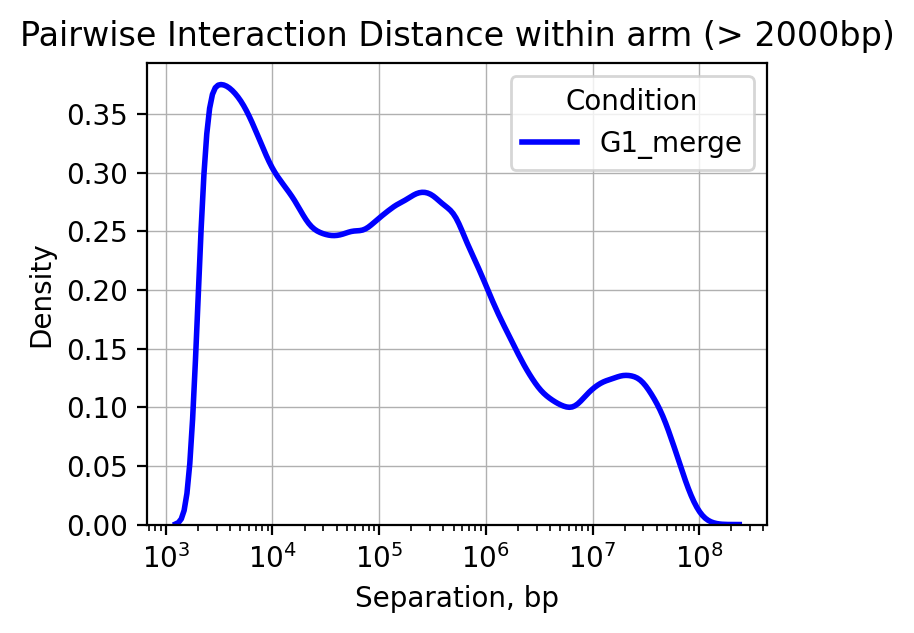

In [67]:
#plot the density of pairwise contaction after filter  
plt.figure(figsize=(4, 3), dpi=200)
fig, ax = plt.subplots(figsize=(4, 3), dpi=200)

sns.kdeplot(data = dist_df, 
            x = 'Abs_Dist',
            common_norm = False,
            lw = 2, 
            log_scale = True, 
            common_grid = True,
            hue='Condition',
            palette=samplecolor)
plt.xlabel('Separation, bp')
plt.ylabel('Density')
plt.title('Pairwise Interaction Distance within arm (> 2000bp)')
plt.grid(lw=0.5)
#plt.legend(bbox_to_anchor=(1.04,1), loc="upper left")

plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot/Benchmark of {cond} pseudobulk Density plot (Distance > {distance}).pdf", 
            format="pdf", bbox_inches="tight")

plt.show()
#sns.move_legend(g, "upper left", bbox_to_anchor=(1.05, 1), title='Sample')

In [14]:
#filter contacts distance > 2000bp 
dist_df = pd.DataFrame() 
cond = 'proM_merge'
samplecolor = {'proM_merge': '#D21404'}
#samplecolor = {'batch1':'#D21404','batch2':'#4E0707','random':"#D9DDDC"}
#for cond in condition:
for batch in ['batch1','batch2']: #or add "random"
        dist_dropna = pd.DataFrame({'Abs_Dist': Pseudobulk_contacts_dfs[cond][batch]['Abs_Dist'],
                                    'Condition': cond})
        dist_dropna = dist_dropna.replace([np.inf, -np.inf], np.nan).dropna()
        dist_df = pd.concat([dist_df, dist_dropna[dist_dropna['Abs_Dist'] > distance]], ignore_index=True)

<Figure size 800x600 with 0 Axes>

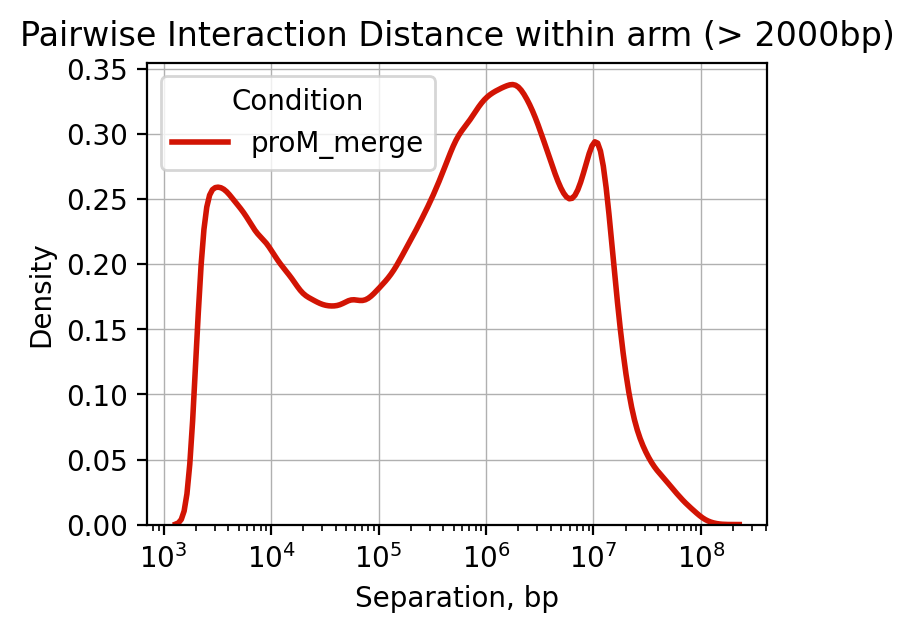

In [15]:
#plot the density of pairwise contaction after filter
plt.figure(figsize=(4, 3), dpi=200)
fig, ax = plt.subplots(figsize=(4, 3), dpi=200)

sns.kdeplot(data = dist_df, 
            x = 'Abs_Dist',
            common_norm = False,
            lw = 2, 
            log_scale = True, 
            common_grid = True,
            hue='Condition',
            palette=samplecolor)
plt.xlabel('Separation, bp')
plt.ylabel('Density')
plt.title('Pairwise Interaction Distance within arm (> 2000bp)')
plt.grid(lw=0.5)
#plt.legend(bbox_to_anchor=(1.04,1), loc="upper left")

plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot/Benchmark of {cond} pseudobulk Density plot (Distance > {distance}).pdf", 
            format="pdf", bbox_inches="tight")


plt.show()
#sns.move_legend(g, "upper left", bbox_to_anchor=(1.05, 1), title='Sample')

In [ ]:
#plot each individual cells

In [6]:
#plot single cell profile of all G1 and proM
path = "/home/xiangru.huo-umw/scHiC/benchmark/scHiC_0115_2023/results_12merge/pairs_library/"

conditions_1 = []
samplecolor = OrderedDict()
col = '#487e71'
for i in range(0,96):
    if (i == 48):
        col = '#ed4141'
    conditions_t = "scHiC_cell_0115_" + str(i+1)
    conditions_1.append(conditions_t)
    samplecolor[conditions_t] = col

os.chdir(path)
os.getcwd()

#get the .pair table
pairs_header = ['read_id', 'chrom1', 'pos1', 'chrom2', 'pos2', 'strand1', 'strand2', 'pair_type', 'mapq1', 'mapq2']

dfs = {}
Num_Contacts = {}
for cond in conditions_1:
    with gzip.open(cond + ".hg38.nodups.pairs.gz", 'rt') as file:
        df = pd.read_csv(file, sep="\t", header=None, comment="#", names=pairs_header, index_col=None)
    
    Num_Cont = np.log10(len(df))
    Num_Contacts[cond] = Num_Cont
    
    df = df.loc[df['chrom1'] == df['chrom2']]
    dfs[cond] = {'df': df}

In [7]:
#get the second batch
path = "/home/xiangru.huo-umw/scHiC/benchmark/scHiC_1203_2022/1+2_sc_results/pairs_library"

conditions_2 = []
samplecolor = OrderedDict()
col = '#487e71'
for i in range(0,96):
    if (i == 48):
        col = '#ed4141'
    conditions_t = "scHiC_cell" + str(i+1)
    conditions_2.append(conditions_t)
    samplecolor[conditions_t] = col

os.chdir(path)
os.getcwd()

for cond in conditions_2:
    with gzip.open(cond + ".hg38.nodups.pairs.gz", 'rt') as file:
        df = pd.read_csv(file, sep="\t", header=None, comment="#", names=pairs_header, index_col=None)
    
    Num_Cont = np.log10(len(df))
    Num_Contacts[cond] = Num_Cont
    
    df = df.loc[df['chrom1'] == df['chrom2']]
    dfs[cond] = {'df': df}

In [ ]:
dfs

{'scHiC_cell_0115_1': {'df':                                                 read_id chrom1      pos1  \
  0            A01940:144:GW2302032824th:4:2122:6126:9064   chr1     10001   
  1      GWNJ-0842:1044:GW2302244735th:2:1201:24251:11330   chr1     10115   
  2      GWNJ-0842:1044:GW2302244735th:2:2113:27925:57776   chr1     10148   
  3      GWNJ-0842:1044:GW2302244735th:2:1123:26189:66724   chr1     10201   
  4       GWNJ-0842:1044:GW2302244735th:2:1207:8095:51553   chr1     10207   
  ...                                                 ...    ...       ...   
  28785   GWNJ-0842:1044:GW2302244735th:2:1211:3468:71278   chrY  19458638   
  28786       A01940:144:GW2302032824th:4:2440:16929:1908   chrY  19458658   
  28787  GWNJ-0842:1044:GW2302244735th:2:1122:28087:36434   chrY  19458680   
  28788  GWNJ-0842:1044:GW2302244735th:2:2207:19421:52397   chrY  26496642   
  28789    GWNJ-0842:1044:GW2302244735th:2:1203:6837:9255   chrY  56834956   
  
        chrom2       pos2 strand1 

In [8]:
#caculate the distance 
dfs_2={}
i=1
ph='G1'
conditions = conditions_1 + conditions_2
for cond in conditions:        
    df = dfs[cond]['df'].copy()
    df = df.loc[:,['chrom1','pos1','chrom2','pos2']]
    #get two position separately
    df["pos1+1"] = df["pos1"] +1
    df["pos2+1"] = df["pos2"] +1
    df_pos1 = df.loc[:,['chrom1','pos1','pos1+1']]
    df_pos1.columns =['chrom', 'start', 'end']
    df_pos2 = df.loc[:,['chrom2','pos2','pos2+1']]
    df_pos2.columns =['chrom', 'start', 'end']
    #get compartment info for each locus
    pos1_arm_intervals = bf.overlap(df_pos1,hg38_arms, how='left', suffixes=('_1','_2'))
    pos2_arm_intervals = bf.overlap(df_pos2,hg38_arms,  how='left', suffixes=('_1','_2'))
    #pick up specific column
    pos1_arm_intervals = pos1_arm_intervals.loc[:,["chrom_1","start_1","arm_2"]]
    pos1_arm_intervals.columns = ["chrom1","pos1","arm1"]
    pos2_arm_intervals = pos2_arm_intervals.loc[:,["chrom_1","start_1","arm_2"]]
    pos2_arm_intervals.columns = ["chrom2","pos2","arm2"]
    #two position organized
    pos1_2 = pd.concat([pos1_arm_intervals,pos2_arm_intervals], axis=1)
    pos1_2 = pos1_2[pos1_2['chrom1'] == pos1_2['chrom2']]
    pos1_2 = pos1_2[pos1_2['arm1'] == pos1_2['arm2']]
    pos1_2['dist'] = pos1_2['pos1']-pos1_2['pos2']
    pos1_2['Abs_Dist'] = abs(pos1_2['dist'].copy()).astype(float)
    pos1_2['Num_Contacts'] = Num_Contacts[cond]
    i = i + 1
    pos1_2['phase'] = ph
    if (cond == 'scHiC_cell_0115_48'):
        ph = 'proM'
    if (cond == 'scHiC_cell_0115_96'):
        ph = 'G1'
    if (cond == 'scHiC_cell48'):
        ph = 'proM'
    dfs_2[cond] = pos1_2

In [19]:
dfs_2['scHiC_cell6']

,chrom1,pos1,arm1,chrom2,pos2,arm2,dist,Abs_Dist,Num_Contacts,phase
0,chr1,10088,p,chr1,10221,p,-133,133.0,4.910539,G1
2,chr1,10189,p,chr1,10374,p,-185,185.0,4.910539,G1
4,chr1,10365,p,chr1,10449,p,-84,84.0,4.910539,G1
5,chr1,16148,p,chr1,16277,p,-129,129.0,4.910539,G1
7,chr1,182659,p,chr1,182776,p,-117,117.0,4.910539,G1
...,...,...,...,...,...,...,...,...,...,...
76586,chrY,56831697,q,chrY,56831782,q,-85,85.0,4.910539,G1
76587,chrY,56834565,q,chrY,56834637,q,-72,72.0,4.910539,G1
76588,chrY,56836233,q,chrY,56836365,q,-132,132.0,4.910539,G1
76589,chrY,56839465,q,chrY,56839524,q,-59,59.0,4.910539,G1


In [9]:
#filter contacts > 2000bp & filter cells > 30K (log = 4.5), > 50K (log = 4.7)or > 100K (log = 5) contacts
dist_df = pd.DataFrame()
dfs_to_concat = []

for cond in conditions:
    dist_dropna = pd.DataFrame({'Abs_Dist': dfs_2[cond]['Abs_Dist'].copy(),
                                'Num_Contacts': dfs_2[cond]['Num_Contacts'].copy(),
                                'phase': dfs_2[cond]['phase'].copy(),
                                'Condition': cond})
    dist_dropna = dist_dropna.replace([np.inf, -np.inf], np.nan).dropna()    
    dfs_to_concat.append(dist_dropna[(dist_dropna['Abs_Dist'] > 2000) & (dist_dropna['Num_Contacts'] > 4.5)])

dist_df = pd.concat(dfs_to_concat, ignore_index=True)

In [12]:
import pickle
with open('/pi/job.dekker-umw/home/xiangru.huo-umw/single_xiangru.plk', 'wb') as file:
    pickle.dump(dist_df, file)

In [22]:
len(dist_df['Condition'].drop_duplicates())

108

In [41]:
dist_df[dist_df['phase']=='G1']

,Abs_Dist,Num_Contacts,phase,Condition
0,2585.0,4.902340,G1,scHiC_cell_0115_3
1,29497186.0,4.902340,G1,scHiC_cell_0115_3
2,29497176.0,4.902340,G1,scHiC_cell_0115_3
3,18942.0,4.902340,G1,scHiC_cell_0115_3
4,2766.0,4.902340,G1,scHiC_cell_0115_3
...,...,...,...,...
2538316,538501.0,5.133389,G1,scHiC_cell48
2538317,45980484.0,5.133389,G1,scHiC_cell48
2538318,25103.0,5.133389,G1,scHiC_cell48
2538319,45540601.0,5.133389,G1,scHiC_cell48


/tmp/ipykernel_3012448/3416545358.py:10: MatplotlibDeprecationWarning: Unable to determine Axes to steal space for Colorbar. Using gca(), but will raise in the future. Either provide the *cax* argument to use as the Axes for the Colorbar, provide the *ax* argument to steal space from it, or add *mappable* to an Axes.
  color_bar = plt.colorbar(plot)


<Figure size 800x600 with 0 Axes>

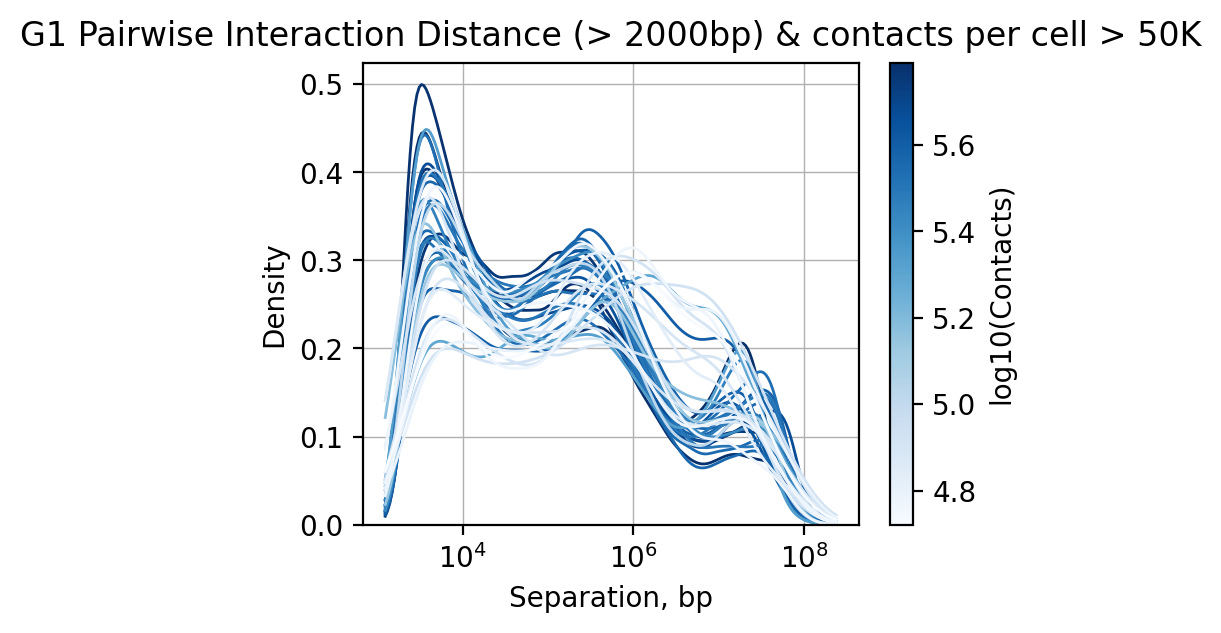

In [ ]:
#plot density of pairs of G1 
plt.figure(figsize=(4, 3), dpi=200)
fig, ax = plt.subplots(figsize=(4, 3), dpi=200)

dist_G1 = dist_df[dist_df['phase'] == 'G1']
dist_G1 = dist_G1[dist_G1['Num_Contacts'] > 4.7]
vals = dist_G1['Num_Contacts'].drop_duplicates().values.tolist()
plot = plt.scatter(np.arange(len(dist_G1['Condition'].drop_duplicates())), np.arange(len(dist_G1['Condition'].drop_duplicates())), c=vals, cmap='Blues')
plt.clf()
color_bar = plt.colorbar(plot)
color_bar.set_label('log10(Contacts)')

ax = sns.kdeplot(data=dist_G1,
                 x='Abs_Dist',
                 common_norm=False,
                 lw=1,
                 log_scale=True,
                 common_grid=True,
                 hue='Num_Contacts',
                 palette='Blues')

plt.xlabel('Separation, bp')
plt.ylabel('Density')
plt.title('G1 Pairwise Interaction Distance (> 2000bp) & contacts per cell > 50K')
plt.grid(lw=0.5)
ax.legend_.remove()

# Save the plot
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot/Benchmark of G1 sc Density plot (Distance > {distance}).pdf")


# Show the plots
plt.show()


/tmp/ipykernel_3012448/1995250913.py:10: MatplotlibDeprecationWarning: Unable to determine Axes to steal space for Colorbar. Using gca(), but will raise in the future. Either provide the *cax* argument to use as the Axes for the Colorbar, provide the *ax* argument to steal space from it, or add *mappable* to an Axes.
  color_bar = plt.colorbar(plot)


<Figure size 800x600 with 0 Axes>

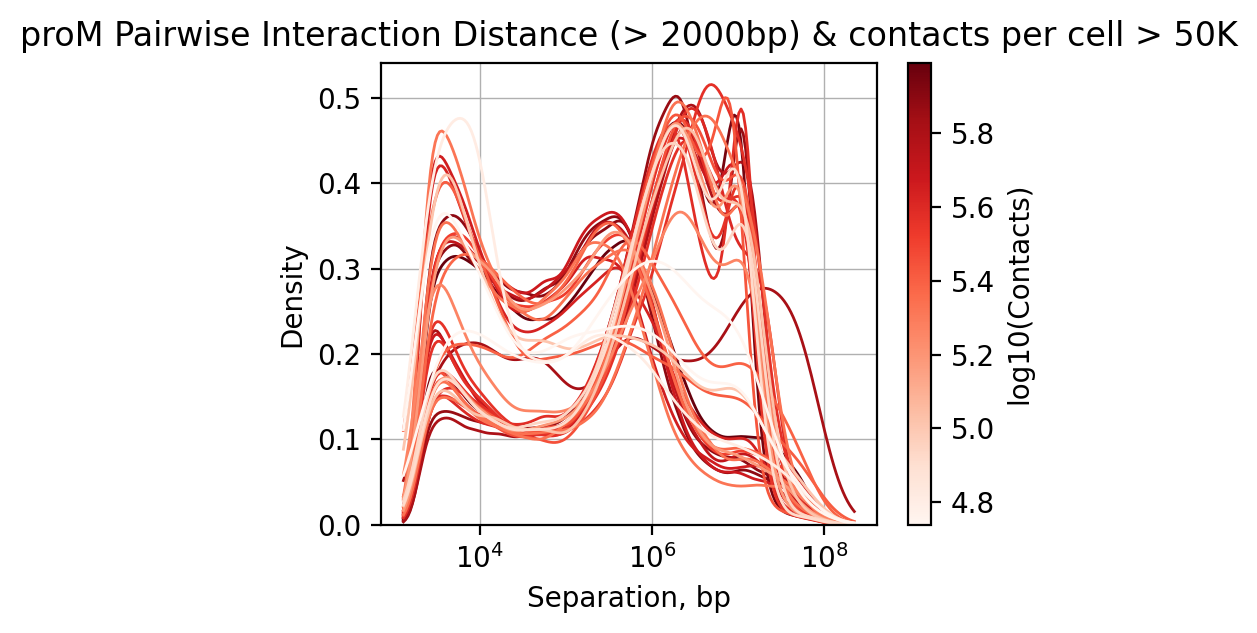

In [ ]:
#plot density of pairs of proM 
plt.figure(figsize=(4, 3), dpi=200)
fig, ax = plt.subplots(figsize=(4, 3), dpi=200)

dist_G1 = dist_df[dist_df['phase'] == 'proM']
dist_G1 = dist_G1[dist_G1['Num_Contacts'] > 4.7]
vals = dist_G1['Num_Contacts'].drop_duplicates().values.tolist()
plot = plt.scatter(np.arange(len(dist_G1['Condition'].drop_duplicates())), np.arange(len(dist_G1['Condition'].drop_duplicates())), c=vals, cmap='Reds')
plt.clf()
color_bar = plt.colorbar(plot)
color_bar.set_label('log10(Contacts)')

ax = sns.kdeplot(data=dist_G1,
                 x='Abs_Dist',
                 common_norm=False,
                 lw=1,
                 log_scale=True,
                 common_grid=True,
                 hue='Num_Contacts',
                 palette='Reds')

plt.xlabel('Separation, bp')
plt.ylabel('Density')
plt.title('proM Pairwise Interaction Distance (> 2000bp) & contacts per cell > 50K')
plt.grid(lw=0.5)
ax.legend_.remove()

# Save the plot
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot/Benchmark of proM sc Density plot (Distance > {distance}).pdf")


# Show the plots
plt.show()

In [124]:
len(dist_proM['Condition'].drop_duplicates())

39

In [125]:
len(dist_G1['Condition'].drop_duplicates())

39